Brianna Aceves | DSC355 | 10.2 Exercise

I duplicated my Week 7 notebook, so the below is related to Week 7's assignment. 

First and foremost, I copied my Week 6 exercise, and making the feedback edits suggested and then adding on to complete Week 7 exercise instructions.

In [1]:
#Install missing library in the current Jupyter environment
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

I add to adjust some things for Week 7's work. I needed to reinstall the seaborn library for this to run again. 

For this exercise, I will use this dataset to build a classification model that predicts the target variable, y. I started by importing the dataset into a Pandas DataFrame. I wanted to look at the first few rows to get a better idea of how the data is organized and what types of values each column contains.

In [50]:
#load the dataset
df = pd.read_csv("eda_classification.csv")

df.head()


,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,x14,x15,x16,x17,y
0,-17.933519,Jun,6.559220,-14.452810,-4.732855,0.381673,2.563194,"($1,306.52)",-89.394348,-28.454044,-16.201298,-0.01%,0.217010,tesla,thurday,9.729891,-0.786431,small,1
1,-37.214754,July,10.774930,-15.384004,-0.077339,10.983774,-15.210206,($24.86),153.032652,-32.557736,69.675903,0.00%,-3.584908,Toyota,thur,35.727926,-0.985552,small,0
2,0.330441,Aug,-19.609972,-9.167911,2.064124,12.071688,12.506141,($110.85),-141.437276,-20.794952,55.042604,0.00%,-3.991366,bmw,wednesday,-9.283523,-3.394718,small,1
3,-13.709765,Aug,-8.011390,6.759264,1.727615,-1.768382,24.039733,($324.43),51.039653,-7.046908,-31.424419,0.01%,7.908897,Toyota,wed,-2.891882,-2.690222,small,0
4,-4.202598,May,7.076210,-26.004919,-4.269696,-3.414224,2.115989,"$1,213.37",-31.046700,19.061182,-31.525515,-0.01%,0.846719,Honda,wednesday,25.497480,3.516801,small,1


Next, I wanted to look at the overall structure of the dataset. This should help me identify which variables are numerical and which ones might need to be cleaned up before building the model.

In [51]:
# Reviewe number of rows and columns
print("Dataset shape:", df.shape)

# Review column names
print("\nColumn names:")
print(df.columns.tolist())

# Review data types
print("\nDataset information:")
df.info()


Dataset shape: (9999, 19)

Column names:
['x0', 'x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9', 'x10', 'x11', 'x12', 'x13', 'x14', 'x15', 'x16', 'x17', 'y']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 9999 entries, 0 to 9998
Data columns (total 19 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x0      9996 non-null   float64
 1   x1      9999 non-null   str    
 2   x2      9995 non-null   float64
 3   x3      9996 non-null   float64
 4   x4      9997 non-null   float64
 5   x5      9997 non-null   float64
 6   x6      9999 non-null   float64
 7   x7      9996 non-null   str    
 8   x8      9998 non-null   float64
 9   x9      9999 non-null   float64
 10  x10     9996 non-null   float64
 11  x11     9997 non-null   str    
 12  x12     9995 non-null   float64
 13  x13     9998 non-null   str    
 14  x14     9997 non-null   str    
 15  x15     9999 non-null   float64
 16  x16     9998 non-null   float64
 17  x17     999

In [5]:
#Descriptive statistics for numerical variables
df.describe().T

,count,mean,std,min,25%,50%,75%,max
x0,9996.0,6.501091,29.140034,-106.809919,-13.094564,6.659263,26.214107,114.823451
x2,9995.0,-3.729880,17.237178,-65.137848,-15.356197,-3.825630,7.764036,67.685933
x3,9996.0,-7.335819,38.355015,-150.846091,-33.079854,-7.374468,18.477979,127.204103
x4,9997.0,-0.001323,3.995307,-14.616540,-2.681308,0.010637,2.635699,16.923269
x5,9997.0,1.347141,9.606695,-37.499530,-5.047927,1.217076,7.807128,38.624213
x6,9999.0,1.214413,17.352962,-59.900503,-10.904697,0.814006,12.693538,68.865261
x8,9998.0,-4.239862,131.921984,-661.764937,-91.489340,-4.744892,83.831778,476.910533
x9,9999.0,-0.297257,37.987287,-142.719688,-25.685742,-0.239779,25.459537,181.063340
x10,9996.0,-22.482050,91.723733,-427.412374,-79.734745,-20.459860,38.383398,319.592518
x12,9995.0,0.034517,6.065264,-25.024464,-4.191568,0.154775,4.136013,21.540626


Before starting on the model, I checked for missing values and duplicates. The descriptive statistics showed that the dataset has 9,999 rows and 19 columns. Also, from looking at the descriptive statistics, I noticed that some numerical values have pretty large ranges, like x8 going from about -661.76 to 476.91, and several columns have fewer than 9,999 non-null values, meaning there are some missing values I'll need to look into before starting the model.

In [6]:
#Check missing values in each column
print("Missing values by column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values by column:
x0     3
x1     0
x2     4
x3     3
x4     2
x5     2
x6     0
x7     3
x8     1
x9     0
x10    3
x11    2
x12    4
x13    1
x14    2
x15    0
x16    1
x17    0
y      0
dtype: int64

Total missing values: 31


In [7]:
#Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


There are no duplicate rows, but this does show me there are 31 missing values. 

In [8]:
#Target distribution
#Count each target value
print(df["y"].value_counts(dropna=False))

#Percentage of each class
print("\nTarget percentages:")
print(df["y"].value_counts(normalize=True) * 100)

y
0    5080
1    4919
Name: count, dtype: int64

Target percentages:
y
0    50.805081
1    49.194919
Name: proportion, dtype: float64


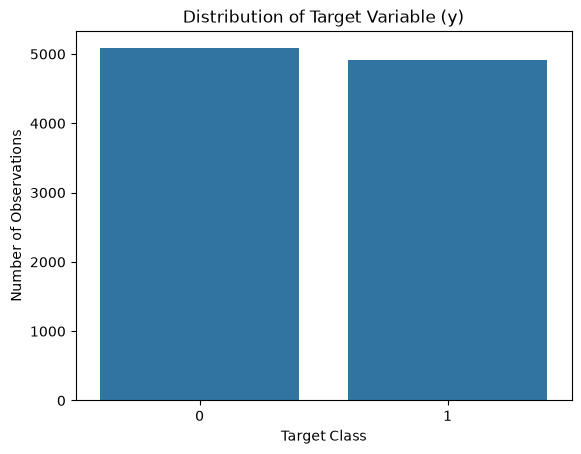

In [9]:
#Plot the target distribution
sns.countplot(data=df, x="y")
plt.title("Distribution of Target Variable (y)")
plt.xlabel("Target Class")
plt.ylabel("Number of Observations")
plt.show()

After looking at the target variable y, I noticed that the two classes are pretty evenly split, with 50.81% being 0 and 49.19% being 1. I want to take a look at the categorical variables to see what kind of values they have and if anything needs to be cleaned up before moving on to the model.

In [10]:
#Identify categorical columns
categorical_cols = df.select_dtypes(
    include=["object", "string"]
).columns.tolist()

print("Categorical columns:", categorical_cols)

#Review unique values and their counts
for col in categorical_cols:
    print(f"\nColumn: {col}")
    print(df[col].value_counts(dropna=False))


Categorical columns: ['x1', 'x7', 'x11', 'x13', 'x14', 'x17']

Column: x1
x1
July       2709
Jun        2357
Aug        2059
May        1144
sept.       912
Apr         413
Oct         246
Mar         116
Nov          27
Feb          10
Dev           5
January       1
Name: count, dtype: int64

Column: x7
x7
($243.22)      3
NaN            3
$63.99         2
($451.04)      2
($344.49)      2
              ..
$1,030.94      1
($1,481.74)    1
$417.34        1
($1,472.62)    1
($863.61)      1
Name: count, Length: 9850, dtype: int64

Column: x11
x11
0.00%     3914
-0.01%    2409
0.01%     2361
0.02%      581
-0.02%     579
0.03%       73
-0.03%      72
-0.04%       4
0.04%        4
NaN          2
Name: count, dtype: int64

Column: x13
x13
volkswagon    3132
Toyota        2773
bmw           1837
Honda         1277
tesla          545
chrystler      291
nissan          90
ford            39
mercades        11
chevrolet        3
NaN              1
Name: count, dtype: int64

Column: x14
x14
w

After looking at the categorical columns, I noticed that some values are written differently even though they mean the same thing, like abbreviations for months or weekdays. I also noticed that some numbers are being treated as text because they include dollar signs or percentages. Next, I wanted to look at the numerical variables a little closer to see how their values are spread out and whether there are any unusual patterns.

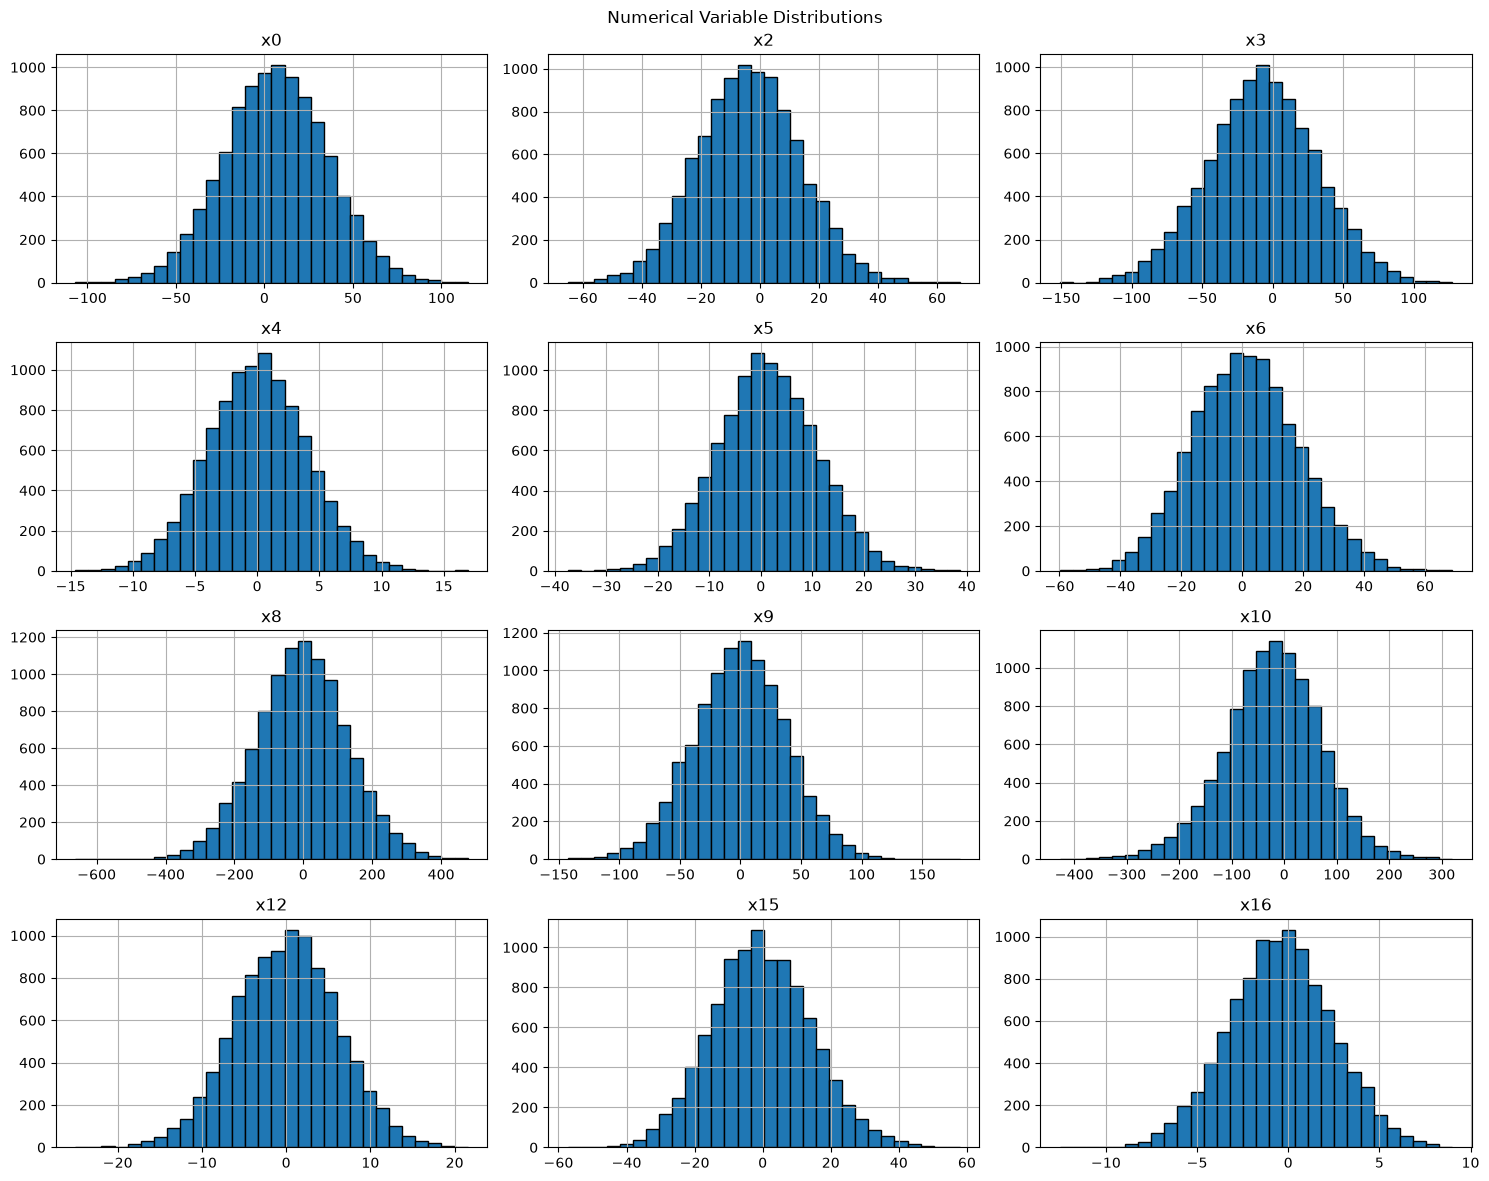

In [11]:
#Numerical Distribution
#Select numerical columns, excluding y
numeric_cols = df.select_dtypes(
    include="number"
).columns.drop("y").tolist()

#Create histograms
df[numeric_cols].hist(
    figsize=(15, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Numerical Variable Distributions")
plt.tight_layout()
plt.show()

I found a few things that need to be cleaned up before building the model. Some columns have currency amounts or percentages that are being read as text, and others have inconsistent abbreviations or spelling. Fixing these will make the data more consistent and then it can actually be used by the classification model.

In [12]:
#Create a copy
df_clean = df.copy()

#Remove extra spaces from column names
df_clean.columns = df_clean.columns.str.strip()

In [13]:
#Check the copy
df_clean.head()

,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,x14,x15,x16,x17,y
0,-17.933519,Jun,6.559220,-14.452810,-4.732855,0.381673,2.563194,"($1,306.52)",-89.394348,-28.454044,-16.201298,-0.01%,0.217010,tesla,thurday,9.729891,-0.786431,small,1
1,-37.214754,July,10.774930,-15.384004,-0.077339,10.983774,-15.210206,($24.86),153.032652,-32.557736,69.675903,0.00%,-3.584908,Toyota,thur,35.727926,-0.985552,small,0
2,0.330441,Aug,-19.609972,-9.167911,2.064124,12.071688,12.506141,($110.85),-141.437276,-20.794952,55.042604,0.00%,-3.991366,bmw,wednesday,-9.283523,-3.394718,small,1
3,-13.709765,Aug,-8.011390,6.759264,1.727615,-1.768382,24.039733,($324.43),51.039653,-7.046908,-31.424419,0.01%,7.908897,Toyota,wed,-2.891882,-2.690222,small,0
4,-4.202598,May,7.076210,-26.004919,-4.269696,-3.414224,2.115989,"$1,213.37",-31.046700,19.061182,-31.525515,-0.01%,0.846719,Honda,wednesday,25.497480,3.516801,small,1


Instead of modfying the original dataframe, I named the copy df_clean and modified the copy instead. 

In [14]:
# Review column x7
# Convert x7 currency amounts to numbers
currency = df_clean["x7"].astype("string").str.strip()

# Identify negative amounts in parentheses
negative = currency.str.startswith("(").fillna(False)

# Remove dollar signs, commas, and parentheses
currency = currency.str.replace(
    r"[$,()\s]", "", regex=True
)

# Convert to numerical values
df_clean["x7"] = pd.to_numeric(
    currency, errors="coerce"
)

# Keep negative amounts
df_clean.loc[negative, "x7"] = (
    -df_clean.loc[negative, "x7"].abs()
)

df_clean["x7"].head(10)


0   -1306.52
1     -24.86
2    -110.85
3    -324.43
4    1213.37
5   -1508.42
6   -1431.44
7    1613.55
8    1178.11
9    -312.04
Name: x7, dtype: Float64

For x7, I noticed that the values included dollar signs, commas, and parentheses, which caused Python to read them as text instead of numbers. I removed the extra formatting and converted the values into numerical data while keeping the negative amounts negative. This should make the column easier to work with when building the classification model.

In [15]:
#Cleaning percentages on x11
#Remove percentage signs and extra spaces
percent = (
    df_clean["x11"]
    .astype("string")
    .str.replace("%", "", regex=False)
    .str.strip()
)

#Convert percentages into decimals
df_clean["x11"] = (
    pd.to_numeric(percent, errors="coerce") / 100
)

#Display the first 10 cleaned values
df_clean["x11"].head(10)


0   -0.0001
1       0.0
2       0.0
3    0.0001
4   -0.0001
5       0.0
6    0.0001
7    0.0001
8       0.0
9       0.0
Name: x11, dtype: Float64

Similar to x7, I noticed that x11 had percentage signs, which caused Python to treat the values as text. I removed the percentage signs and converted everything into decimals so the model can recognize them as numerical values.

In [16]:
#Standardize
#Identify remaining categorical columns
category_cols = df_clean.select_dtypes(
    include=["object", "string"]
).columns.tolist()

#Convert to lowercase and remove extra spaces
for col in category_cols:
    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

#Standardize month names
month_map = {
    "jan": "january",
    "feb": "february",
    "mar": "march",
    "apr": "april",
    "jun": "june",
    "jul": "july",
    "aug": "august",
    "sep": "september",
    "sept": "september",
    "sept.": "september",
    "oct": "october",
    "nov": "november",
    "dec": "december"
}

df_clean["x1"] = df_clean["x1"].replace(month_map)

#Standardize weekday names
day_map = {
    "mon": "monday",
    "tue": "tuesday",
    "tues": "tuesday",
    "wed": "wednesday",
    "weds": "wednesday",
    "thur": "thursday",
    "thurs": "thursday",
    "thurday": "thursday",
    "fri": "friday",
    "sat": "saturday",
    "sun": "sunday"
}

df_clean["x14"] = df_clean["x14"].replace(day_map)

#Standardize car brand spelling
df_clean["x13"] = df_clean["x13"].replace({
    "volkswagon": "volkswagen",
    "chrystler": "chrysler"
})

#Review the cleaned categories
for col in category_cols:
    print(f"\nColumn: {col}")
    print(df_clean[col].value_counts(dropna=False))



Column: x1
x1
july         2709
june         2357
august       2059
may          1144
september     912
april         413
october       246
march         116
november       27
february       10
dev             5
january         1
Name: count, dtype: Int64

Column: x13
x13
volkswagen    3132
toyota        2773
bmw           1837
honda         1277
tesla          545
chrysler       291
nissan          90
ford            39
mercades        11
chevrolet        3
<NA>             1
Name: count, dtype: Int64

Column: x14
x14
wednesday    5198
thursday     4433
tuesday       214
friday        137
monday         15
<NA>            2
Name: count, dtype: Int64

Column: x17
x17
small     8849
medium     783
large      367
Name: count, dtype: Int64


I cleaned up the categorical variables because some of the values were written differently. For example, some months and weekdays were abbreviated, and a few categories had spelling differences. I converted everything to lowercase and standardized the names so they would be treated as the same category instead of separate ones.

In [17]:
#Review updated data types
print("Updated data types:")
print(df_clean.dtypes)

#Check remaining missing values
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

#Compare missing values before and after cleaning
print("\nChange in missing values:")
print(
    df_clean.isnull().sum() - df.isnull().sum()
)

#Display first five rows
df_clean.head()

Updated data types:
x0     float64
x1      string
x2     float64
x3     float64
x4     float64
x5     float64
x6     float64
x7     Float64
x8     float64
x9     float64
x10    float64
x11    Float64
x12    float64
x13     string
x14     string
x15    float64
x16    float64
x17     string
y        int64
dtype: object

Missing values after cleaning:
x0     3
x1     0
x2     4
x3     3
x4     2
x5     2
x6     0
x7     3
x8     1
x9     0
x10    3
x11    2
x12    4
x13    1
x14    2
x15    0
x16    1
x17    0
y      0
dtype: int64

Change in missing values:
x0     0
x1     0
x2     0
x3     0
x4     0
x5     0
x6     0
x7     0
x8     0
x9     0
x10    0
x11    0
x12    0
x13    0
x14    0
x15    0
x16    0
x17    0
y      0
dtype: int64


,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,x14,x15,x16,x17,y
0,-17.933519,june,6.559220,-14.452810,-4.732855,0.381673,2.563194,-1306.52,-89.394348,-28.454044,-16.201298,-0.0001,0.217010,tesla,thursday,9.729891,-0.786431,small,1
1,-37.214754,july,10.774930,-15.384004,-0.077339,10.983774,-15.210206,-24.86,153.032652,-32.557736,69.675903,0.0,-3.584908,toyota,thursday,35.727926,-0.985552,small,0
2,0.330441,august,-19.609972,-9.167911,2.064124,12.071688,12.506141,-110.85,-141.437276,-20.794952,55.042604,0.0,-3.991366,bmw,wednesday,-9.283523,-3.394718,small,1
3,-13.709765,august,-8.011390,6.759264,1.727615,-1.768382,24.039733,-324.43,51.039653,-7.046908,-31.424419,0.0001,7.908897,toyota,wednesday,-2.891882,-2.690222,small,0
4,-4.202598,may,7.076210,-26.004919,-4.269696,-3.414224,2.115989,1213.37,-31.046700,19.061182,-31.525515,-0.0001,0.846719,honda,wednesday,25.497480,3.516801,small,1


After cleaning the data, I checked the column types and missing values again to make sure everything worked. Both x7 and x11 are now numerical and the cleaning didn't create any new missing values. There are still a few missing values in some columns but I'll handle those during preprocessing instead of removing the rows.

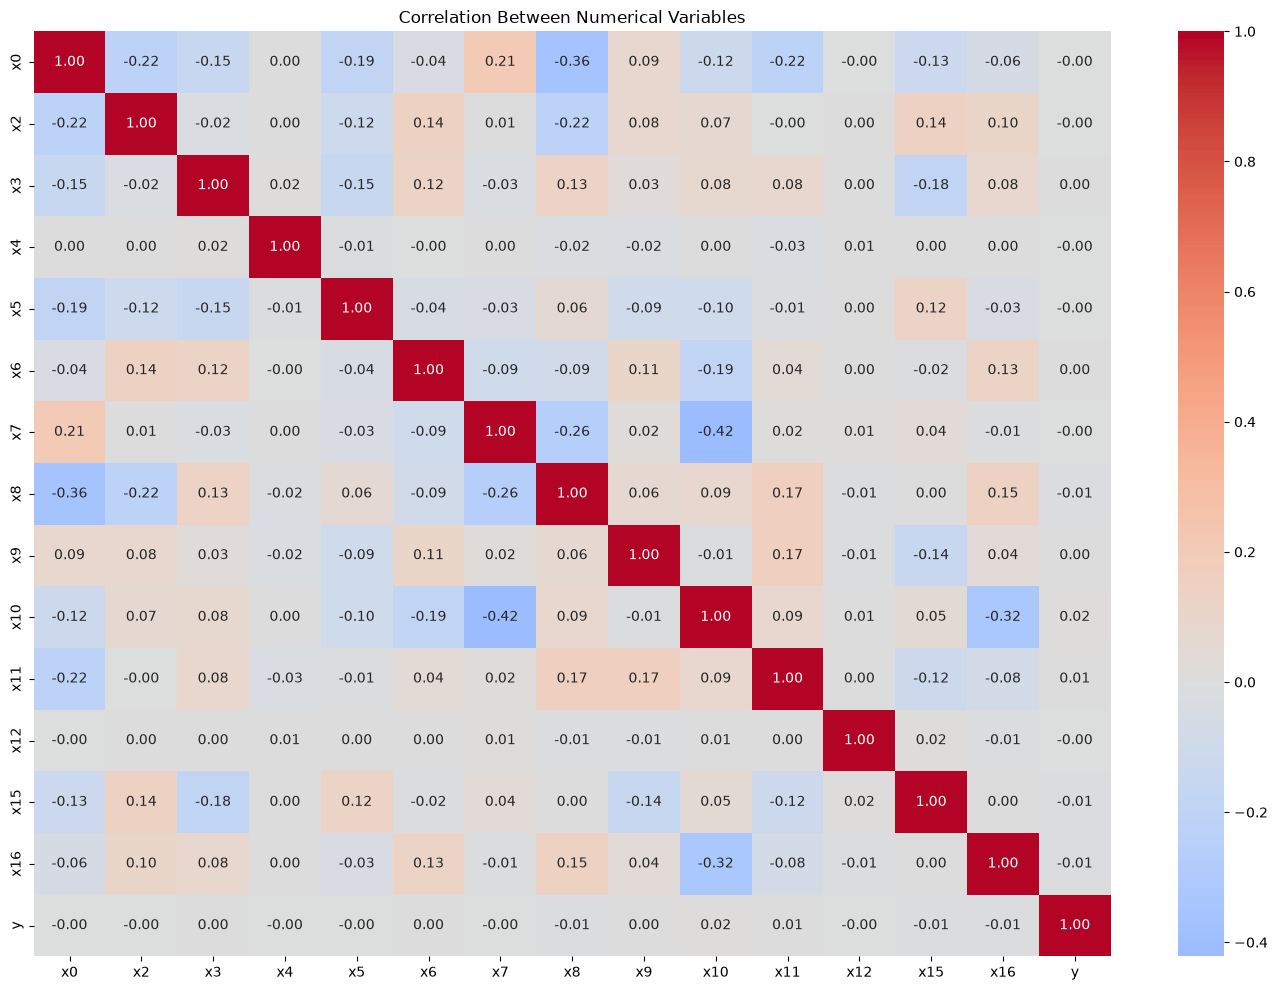

In [18]:
#Checking correlations
#Select numerical columns
numerical_data = df_clean.select_dtypes(
    include="number"
)

#Calculate correlations
correlation_matrix = numerical_data.corr()

#Create correlation heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()


I used a correlation heatmap to see how the numerical variables relate to each other and to the target variable, y. I wanted to get a better idea of whether any features have stronger positive or negative relationships that could help with the classification model.

In [19]:
#Separate the predictor variables from the target
X = df_clean.drop(columns=["y"]).copy()
y = df_clean["y"]

#Check target values
print("Target values:", y.unique())

#Review dataset shapes
print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

Target values: [1 0]
Predictor shape: (9999, 18)
Target shape: (9999,)


I've finished cleaning and exploring the data, I separated the predictors from the target variable. X contains the 18 features the model will use to make predictions, while y contains the actual 0 or 1 outcomes. This will help me prepare everything for training and testing.

In [20]:
#Identify categorical columns
cat_cols = X.select_dtypes(
    include=["object", "string"]
).columns.tolist()

#Convert categorical columns to object type
#use np.nan for missing values
for col in cat_cols:
    X[col] = X[col].astype(object)
    X[col] = X[col].where(
        X[col].notna(), np.nan
    )

#Display categorical columns
print("Categorical columns:", cat_cols)

#Check missing values
print("\nMissing values in predictors:")
print(X.isnull().sum())


Categorical columns: ['x1', 'x13', 'x14', 'x17']

Missing values in predictors:
x0     3
x1     0
x2     4
x3     3
x4     2
x5     2
x6     0
x7     3
x8     1
x9     0
x10    3
x11    2
x12    4
x13    1
x14    2
x15    0
x16    1
x17    0
dtype: int64


I also made sure the categorical columns were in a format that Scikit-learn could work with. Since there are still a few missing values in the dataset, I'm keeping track of those so they can be filled in during preprocessing. This way, I don't have to delete rows just because they're missing a small amount of information.

In [21]:
#Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

#Review the sizes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

#Check the target distribution
print("\nTraining target percentages:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target percentages:")
print(y_test.value_counts(normalize=True) * 100)

Training data: (7999, 18)
Testing data: (2000, 18)

Training target percentages:
y
0    50.806351
1    49.193649
Name: proportion, dtype: float64

Testing target percentages:
y
0    50.8
1    49.2
Name: proportion, dtype: float64


I split the data into 80% for training and 20% for testing, which gave me 7,999 rows for training and 2,000 for testing. I also used stratification since the original target was almost evenly split between 0 and 1. This helps keep both classes fairly equal when training and testing the model.

In [22]:
#Identify numerical and categorical features
numeric_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "string"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

#Prepare numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

#Prepare categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

#Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("\nPreprocessing pipeline created successfully!")


Numerical features: ['x0', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9', 'x10', 'x11', 'x12', 'x15', 'x16']
Categorical features: ['x1', 'x13', 'x14', 'x17']

Preprocessing pipeline created successfully!


Since the dataset has both numerical and categorical variables, I needed to prepare them differently before training the model. I set up one-hot encoding for the categorical columns and standardization for the numerical ones since their values have pretty different ranges. I also filled in the remaining missing values with the median.

In [23]:
#Create the logistic regression model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

#Train the model
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


Now that the features are prepared, I trained a logistic regression model to predict y. I chose logistic regression because the target is binary.

In [24]:
#Make predictions using the testing data
y_pred = model.predict(X_test)

#Compare predictions to actual values
results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})

#Check whether the prediction was correct
results["Correct"] = (
    results["Actual"] == results["Predicted"]
)

#Display the first 15 predictions
results.head(15)

,Actual,Predicted,Correct
0,0,0,True
1,0,0,True
2,0,0,True
3,0,0,True
4,1,0,False
5,1,0,False
6,0,0,True
7,1,1,True
8,0,1,False
9,0,1,False


After training the model, I compared the predicted values with the actual values of y to see how well it performed. Looking at the first 15 predictions, the model got 10 correct and 5 incorrect. I want to check the overall accuracy to get a better idea of how well the model performed on the entire testing dataset.

In [25]:
#Evaluate model
#Calculate overall accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.2%}")

#Display the classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))


Model Accuracy: 51.60%

Classification Report:
              precision    recall  f1-score   support

           0       0.52      0.60      0.56      1016
           1       0.51      0.43      0.47       984

    accuracy                           0.52      2000
   macro avg       0.52      0.51      0.51      2000
weighted avg       0.52      0.52      0.51      2000



After checking the model's performance, I found that it had an overall accuracy of 51.60%, which is pretty low. Looking at the classification report, the model did a little better predicting 0, with a recall of 0.60 compared to 0.43 for 1. The F1-scores were also fairly low at 0.56 for 0 and 0.47 for 1. Overall, it looks like the model is struggling to identify both classes accurately, especially 1.

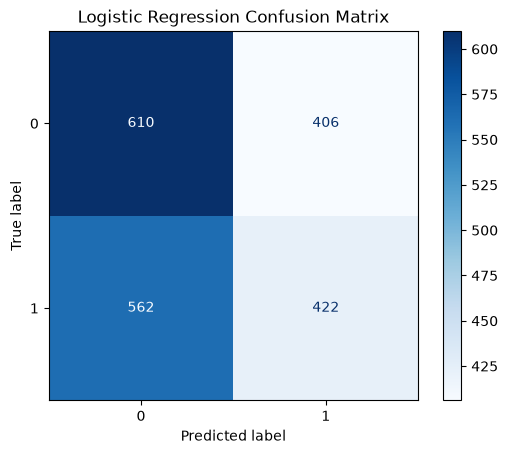

In [26]:
#Create confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

#Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression Confusion Matrix")
plt.show()

Looking at the confusion matrix, the model correctly predicted 610 values of 0 and 422 values of 1, but it also made quite a few mistakes. It incorrectly predicted 406 values as 1 and 562 values as 0, which shows that it struggled more with identifying class 1. This lines up with the 51.60% accuracy from the classification report and shows that the model isn't making very reliable predictions yet.

In [27]:
#Compare to Baseline
#Find the most common class in the training data
majority_class = y_train.mode()[0]

#Create baseline predictions
baseline_pred = np.full(
    len(y_test),
    majority_class
)

#Calculate baseline accuracy
baseline_accuracy = accuracy_score(
    y_test,
    baseline_pred
)

#Compare baseline and logistic regression
print(f"Baseline Accuracy: {baseline_accuracy:.2%}")
print(f"Logistic Regression Accuracy: {accuracy:.2%}")

#Calculate the difference
improvement = (accuracy - baseline_accuracy) * 100

print(
    f"Accuracy Difference: "
    f"{improvement:.2f} percentage points"
)

Baseline Accuracy: 50.80%
Logistic Regression Accuracy: 51.60%
Accuracy Difference: 0.80 percentage points


I compared my logistic regression model to a baseline that always predicts the most common class. The baseline had an accuracy of 50.80%, while my logistic regression model reached 51.60%, which is only a 0.80 percentage point improvement. Although the model did slightly better, the difference is pretty small, which tells me it might not be finding many useful patterns in the data.

Starting Week 7 Exercise | In Week 6, I created a logistic regression classification model to predict the binary target variable, y. The initial model achieved an accuracy of about 51.6%, which was only slightly higher than the majority-class baseline of about 50.8%. For this exercise in Week 7, I will evaluate the model using additional classification metrics and then use cross-validation and hyperparameter tuning to see whether the model's performance can be improved. I will compare the tuned model with the original logistic regression model using the same testing dataset.

In [28]:
#Import 
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("Additional evaluation and tuning tools imported successfully.")

Additional evaluation and tuning tools imported successfully.


The original model was evaluated using accuracy, a classification report, and a confusion matrix. For this exercise, I also want to calculate precision, recall, F1-score, and ROC-AUC. I also imported GridSearchCV and StratifiedKFold so I can test different logistic regression settings using cross-validation. Stratified cross-validation is useful for classification because it helps keep the proportion of each target class similar across the folds.

In [29]:
#Generate predictions from the original logistic regression model
original_pred = model.predict(X_test)

#Probability that each observation belongs to class 1
original_prob = model.predict_proba(X_test)[:, 1]

print("Original model predictions generated successfully.")

Original model predictions generated successfully.


I first generated predictions from the original logistic regression model. These predictions will be used to calculate a more complete set of classification metrics. This gives me a baseline model that I can compare with the tuned model later. And to avoid confusion I used original_pred over baseline_pred. 

In [30]:
#Calculate baseline classification metrics
original_accuracy = accuracy_score(
    y_test,
    original_pred
)

original_precision = precision_score(
    y_test,
    original_pred,
    zero_division=0
)

original_recall = recall_score(
    y_test,
    original_pred,
    zero_division=0
)

original_f1 = f1_score(
    y_test,
    original_pred,
    zero_division=0
)

original_auc = roc_auc_score(
    y_test,
    original_prob
)

print("Original Logistic Regression Evaluation")
print(f"Accuracy:  {original_accuracy:.4f}")
print(f"Precision: {original_precision:.4f}")
print(f"Recall:    {original_recall:.4f}")
print(f"F1-Score:  {original_f1:.4f}")
print(f"ROC-AUC:   {original_auc:.4f}")

Original Logistic Regression Evaluation
Accuracy:  0.5160
Precision: 0.5097
Recall:    0.4289
F1-Score:  0.4658
ROC-AUC:   0.5153


Accuracy tells me how many predictions were correct overall, but accuracy alone does not show what kinds of mistakes the model is making. I calculated precision, recall, F1-score, and ROC-AUC in addition to accuracy. Accuracy measures the percentage of all predictions that were correct. Precision measures how often predictions of class 1 were actually class 1. Recall measures how many of the actual class 1 observations the model successfully identified.F1-score balances precision and recall into one measurement. ROC-AUC measures how well the model separates the two classes across different classification thresholds. Looking at several metrics gives me a more complete picture of how well the classification model performs.

In [31]:
#Re-evaluate the model 
print(
    classification_report(
        y_test,
        original_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.52      0.60      0.56      1016
           1       0.51      0.43      0.47       984

    accuracy                           0.52      2000
   macro avg       0.52      0.51      0.51      2000
weighted avg       0.52      0.52      0.51      2000



I reviewed the classification report to compare how the model performed for both classes. The model performed better at identifying class 0 than class 1 in my original report.For class 0, the recall was 0.60, which means the model correctly identified about 60% of the actual class 0 observations. For class 1, the recall was lower at 0.43, meaning the model missed more of the actual class 1 observations. The F1-score was also higher for class 0 at 0.56 compared with 0.47 for class 1. Overall accuracy was about 52%, and the macro and weighted averages were both around 0.51–0.52. This tells me that the model is only slightly better than random guessing and has more difficulty identifying class 1 correctly.

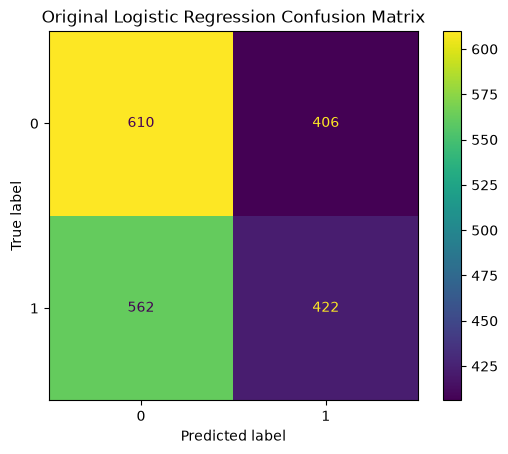

In [32]:
#Create confusion matrix
original_cm = confusion_matrix(
    y_test,
    original_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=original_cm,
    display_labels=[0, 1]
)

disp.plot(values_format="d")

plt.title("Original Logistic Regression Confusion Matrix")
plt.show()

The confusion matrix gives me a closer look at the predictions made by the original logistic regression model. The model correctly predicted 610 observations as class 0 and 422 observations as class 1. It incorrectly predicted 406 class 0 observations as class 1 and incorrectly predicted 562 class 1 observations as class 0. The largest error was the 562 false negatives, meaning the model had more difficulty identifying actual class 1 observations. This matches the classification report, where class 1 had a lower recall score of 0.43 compared with 0.60 for class 0.

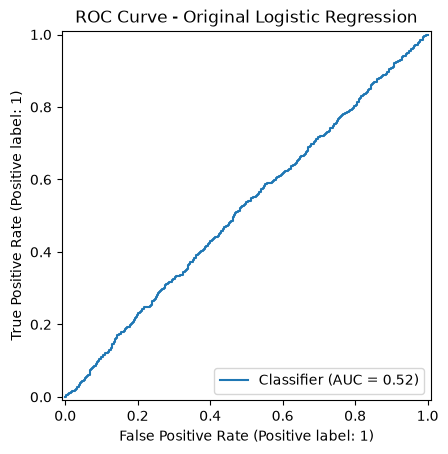

In [33]:
#Create ROC curve for the original model
RocCurveDisplay.from_predictions(
    y_test,
    original_prob
)

plt.title("ROC Curve - Original Logistic Regression")
plt.show()

I created an ROC curve to see how well the original logistic regression model can separate class 0 from class 1 across different classification thresholds. The ROC-AUC score was 0.52. Since an AUC of 0.50 represents performance close to random guessing, this shows me that the model currently has very little ability to distinguish between the two classes. The ROC curve also stays fairly close to the diagonal line, which supports this result. This matches what I saw with the other evaluation metrics. The model's accuracy was only about 52%, and it had difficulty correctly identifying class 1. This gives me another reason to test whether tuning the logistic regression model can improve its performance.

In [34]:
#Create a summary table of the original model metrics
original_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Original Model": [
        original_accuracy,
        original_precision,
        original_recall,
        original_f1,
        original_auc
    ]
})

display(original_metrics)

,Metric,Original Model
0,Accuracy,0.516000
1,Precision,0.509662
2,Recall,0.428862
3,F1-Score,0.465784
4,ROC-AUC,0.515252


I placed the main classification metrics into one table so I could review the overall performance of the original logistic regression model more easily. This table also gives me a baseline that I can use later when comparing the original model with the tuned model. Instead of looking only at accuracy, I can compare changes in precision, recall, F1-score, and ROC-AUC as well.

In [35]:
#Create 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-fold stratified cross-validation created.")

5-fold stratified cross-validation created.


I created a 5-fold stratified cross-validation process to use during model tuning. This divides the training data into five sections and repeatedly trains and validates the model using different sections of the data. I used StratifiedKFold because this is a classification problem. Stratification helps keep a similar proportion of class 0 and class 1 observations in each fold, which makes the validation results more consistent.

In [36]:
#Create the parameter grid for logistic regression
param_grid = {
    "classifier__C": [
        0.01,
        0.1,
        1,
        10,
        100
    ],
    "classifier__penalty": [
        "l1",
        "l2"
    ],
    "classifier__solver": [
        "liblinear"
    ]
}

print("Parameter grid created.")

Parameter grid created.


I created a parameter grid to test different regularization settings for logistic regression. The C parameter controls the strength of regularization. Smaller C values apply stronger regularization, while larger values apply less. I also tested both L1 and L2 penalties to see whether either approach improved the model. This gives GridSearchCV a lot of combinations to compare instead of relying only on the default logistic regression settings.

In [37]:
#Create GridSearchCV
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    return_train_score=True
)

#Fit using training data only
grid_search.fit(
    X_train,
    y_train
)

print("Hyperparameter tuning complete.")

Hyperparameter tuning complete.


C:\Users\brian\anaconda3\envs\dsc360_use\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


I used GridSearchCV to test the different logistic regression parameter combinations using 5-fold stratified cross-validation. I chose F1-score as the scoring metric because my original model had more difficulty identifying class 1. F1-score considers both precision and recall, so it gives me a better way to evaluate the balance between the two. The grid search was performed only on the training data so the testing data could remain separate for the final evaluation.

In [38]:
#Review the best Parameters
#Display the best parameters and cross-validation score
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(
    round(
        grid_search.best_score_,
        4
    )
)

Best Parameters:
{'classifier__C': 100, 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear'}

Best Cross-Validation F1-Score:
0.4283


From the grid search, I found that the best settings were a C value of 100, an L2 penalty, and the liblinear solver. The best cross-validation F1-score was 0.4283. The larger C value tells me that the better-performing version of the model used less regularization. I also found that L2 performed better than L1 for the combinations I tested. Even though this was the best result from the grid search, the F1-score was still only about 0.43. This makes me think the tuning may only improve the model a little, so I still need to compare the tuned model with the original model on the test data before deciding if it really performed better.

In [39]:
#Convert GridSearchCV results into a DataFrame
cv_results = pd.DataFrame(
    grid_search.cv_results_
)

#Select the most useful columns
tuning_results = cv_results[[
    "param_classifier__C",
    "param_classifier__penalty",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]].copy()

#Rename columns
tuning_results = tuning_results.rename(
    columns={
        "param_classifier__C": "C",
        "param_classifier__penalty": "Penalty",
        "mean_test_score": "Mean CV F1",
        "std_test_score": "CV F1 Std Dev",
        "rank_test_score": "Rank"
    }
)

#Display results from best to worst
display(
    tuning_results.sort_values("Rank")
)

,C,Penalty,Mean CV F1,CV F1 Std Dev,Rank
9,100.00,l2,0.428316,0.008926,1
6,10.00,l1,0.428074,0.009391,2
8,100.00,l1,0.428034,0.008718,3
5,1.00,l2,0.427953,0.010034,4
7,10.00,l2,0.427575,0.009185,5
3,0.10,l2,0.425370,0.010043,6
4,1.00,l1,0.424892,0.012864,7
1,0.01,l2,0.407281,0.013953,8
2,0.10,l1,0.383217,0.025539,9
0,0.01,l1,0.000000,0.000000,10


The best result used a C value of 100 with an L2 penalty and had a mean F1-score of about 0.4283. Most of the stronger models had C values of 10 or 100, while smaller C values generally performed worse. The C value of 0.01 with an L1 penalty performed the worst with an F1-score of 0. This suggests that too much regularization hurt the model. Overall, tuning changed the results slightly, but the best F1-scores still stayed around 0.43.

In [40]:
#Save the best model found by GridSearchCV
tuned_model = grid_search.best_estimator_

#Generate predictions using the test set
tuned_pred = tuned_model.predict(
    X_test
)

#Generate probabilities for class 1
tuned_prob = tuned_model.predict_proba(
    X_test
)[:, 1]

print("Tuned model predictions generated.")

Tuned model predictions generated.


I saved the best model selected by GridSearchCV and used it to make predictions on the original testing dataset. The testing data was not used during hyperparameter tuning, so it provides a better way to evaluate how well the tuned model performs on new data.

In [41]:
#Calculate evaluation metrics for the tuned model
tuned_accuracy = accuracy_score(
    y_test,
    tuned_pred
)

tuned_precision = precision_score(
    y_test,
    tuned_pred,
    zero_division=0
)

tuned_recall = recall_score(
    y_test,
    tuned_pred,
    zero_division=0
)

tuned_f1 = f1_score(
    y_test,
    tuned_pred,
    zero_division=0
)

tuned_auc = roc_auc_score(
    y_test,
    tuned_prob
)

print("Tuned Logistic Regression Evaluation")
print(f"Accuracy:  {tuned_accuracy:.4f}")
print(f"Precision: {tuned_precision:.4f}")
print(f"Recall:    {tuned_recall:.4f}")
print(f"F1-Score:  {tuned_f1:.4f}")
print(f"ROC-AUC:   {tuned_auc:.4f}")

Tuned Logistic Regression Evaluation
Accuracy:  0.5160
Precision: 0.5097
Recall:    0.4278
F1-Score:  0.4652
ROC-AUC:   0.5155


The tuned logistic regression model had an accuracy of 0.5160, with precision at 0.5097, recall at 0.4278, and an F1-score of 0.4652. The ROC-AUC score was 0.5155. These results are very close to the original model, so the tuning did not make a major difference in performance. The recall and F1-score for class 1 are still fairly low, which shows that the model continues to have difficulty correctly identifying class 1.

In [42]:
#Display classification report for tuned model
print(
    classification_report(
        y_test,
        tuned_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.52      0.60      0.56      1016
           1       0.51      0.43      0.47       984

    accuracy                           0.52      2000
   macro avg       0.52      0.51      0.51      2000
weighted avg       0.52      0.52      0.51      2000



The tuned classification report looks almost the same as the original model. Class 0 still had a recall of 0.60 and an F1-score of 0.56, while class 1 had a lower recall of 0.43 and an F1-score of 0.47. This shows that tuning did not really change how the model handled the two classes. The model still performs better at identifying class 0 and continues to have more difficulty correctly identifying class 1.

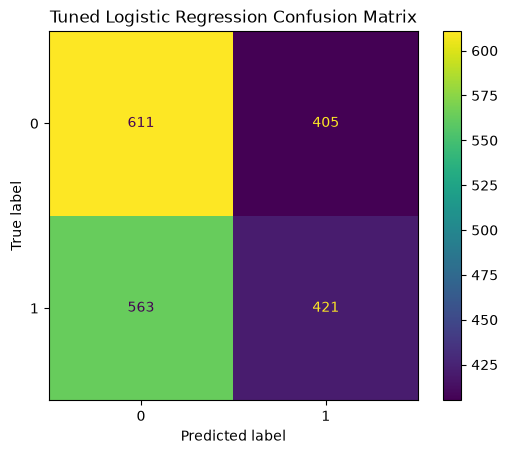

In [43]:
#Create confusion matrix for the tuned model
tuned_cm = confusion_matrix(
    y_test,
    tuned_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=tuned_cm,
    display_labels=[0, 1]
)

disp.plot(values_format="d")

plt.title("Tuned Logistic Regression Confusion Matrix")
plt.show()

The tuned confusion matrix was almost identical to the original model. The tuned model correctly predicted 611 class 0 observations and 421 class 1 observations. It also produced 405 false positives and 563 false negatives. Compared with the original model, the changes were only by one prediction in each area. This confirms that hyperparameter tuning did not meaningfully improve the model. The model still has the most difficulty with false negatives, meaning it continues to miss many actual class 1 observations.

In [44]:
#Create comparison table
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Original Model": [
        original_accuracy,
        original_precision,
        original_recall,
        original_f1,
        original_auc
    ],
    "Tuned Model": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        tuned_auc
    ]
})

#Calculate the change
comparison["Change"] = (
    comparison["Tuned Model"]
    - comparison["Original Model"]
)

display(comparison)

,Metric,Original Model,Tuned Model,Change
0,Accuracy,0.516000,0.516000,0.000000
1,Precision,0.509662,0.509685,0.000023
2,Recall,0.428862,0.427846,-0.001016
3,F1-Score,0.465784,0.465193,-0.000590
4,ROC-AUC,0.515252,0.515536,0.000284


The comparison shows that the tuned model performed almost the same as the original model. Accuracy stayed the same, precision increased a very slight amount, while recall, and F1-score decreased by very small (almost insignificant) amounts. ROC-AUC stayed essentially unchanged. These differences are so small that I would not consider the tuned model to be meaningfully better. Overall, changing the logistic regression settings did not improve the model much.

In [45]:
#Compare with the Majority class Baseline
#Find the most common class in the training data
majority_class = y_train.mode()[0]

#Predict the majority class for every test observation
majority_pred = np.full(
    len(y_test),
    majority_class
)

#Calculate majority baseline accuracy
majority_accuracy = accuracy_score(
    y_test,
    majority_pred
)

print(
    f"Majority Baseline Accuracy: "
    f"{majority_accuracy:.4f}"
)

print(
    f"Original Logistic Regression Accuracy: "
    f"{original_accuracy:.4f}"
)

print(
    f"Tuned Logistic Regression Accuracy: "
    f"{tuned_accuracy:.4f}"
)

Majority Baseline Accuracy: 0.5080
Original Logistic Regression Accuracy: 0.5160
Tuned Logistic Regression Accuracy: 0.5160


The majority-class baseline had an accuracy of 0.5080, while both logistic regression models had an accuracy of about 0.5160. So the models performed slightly better than simply predicting the most common class every time, but the improvement was super small. This supports the other results showing that the current logistic regression model is only learning a weak pattern from the predictor variables.

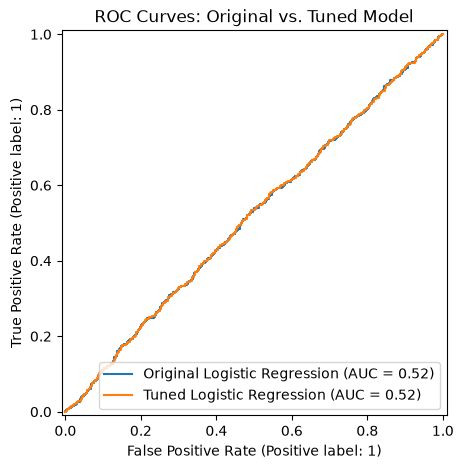

In [46]:
#Compare ROC curves on the same graph
fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_predictions(
    y_test,
    original_prob,
    name="Original Logistic Regression",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    tuned_prob,
    name="Tuned Logistic Regression",
    ax=ax
)

plt.title("ROC Curves: Original vs. Tuned Model")
plt.show()

The ROC curves for the original and tuned logistic regression models are almost identical, and both have an AUC of about 0.52. This shows that tuning did not improve the model’s ability to separate class 0 from class 1. Since an AUC close to 0.50 is similar to random guessing, both models still have weak classification performance.

In [47]:
#Display final model comparison
print("----FINAL MODEL COMPARISON----")

print("\nOriginal Logistic Regression")
print(f"Accuracy:  {original_accuracy:.4f}")
print(f"Precision: {original_precision:.4f}")
print(f"Recall:    {original_recall:.4f}")
print(f"F1-Score:  {original_f1:.4f}")
print(f"ROC-AUC:   {original_auc:.4f}")

print("\nBest Hyperparameters")
print(grid_search.best_params_)

print("\nTuned Logistic Regression")
print(f"Accuracy:  {tuned_accuracy:.4f}")
print(f"Precision: {tuned_precision:.4f}")
print(f"Recall:    {tuned_recall:.4f}")
print(f"F1-Score:  {tuned_f1:.4f}")
print(f"ROC-AUC:   {tuned_auc:.4f}")

print(
    f"\nMajority Baseline Accuracy: "
    f"{majority_accuracy:.4f}"
)

----FINAL MODEL COMPARISON----

Original Logistic Regression
Accuracy:  0.5160
Precision: 0.5097
Recall:    0.4289
F1-Score:  0.4658
ROC-AUC:   0.5153

Best Hyperparameters
{'classifier__C': 100, 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear'}

Tuned Logistic Regression
Accuracy:  0.5160
Precision: 0.5097
Recall:    0.4278
F1-Score:  0.4652
ROC-AUC:   0.5155

Majority Baseline Accuracy: 0.5080


The final comparison shows that the original and tuned logistic regression models performed almost the same. Both had an accuracy of 0.5160, and the precision, recall, F1-score, and ROC-AUC values were also nearly identical. The tuned model used a C value of 100 with an L2 penalty and the liblinear solver, but these settings did not lead to a meaningful improvement. Both models were only slightly better than the majority baseline accuracy of 0.5080. Overall, the results suggest that changing the logistic regression settings was not enough to improve the model much. The next step may be to revisit the features or try a different classification algorithm.

START of Week 10 (10.2 Exercise)

In [52]:
#Import Joblib to save the trained model
import joblib

#Prepare the model and test data for the dashboard
dashboard_data = {
    "model": tuned_model,
    "X_test": X_test,
    "y_test": y_test
}

#Save the model and test data
joblib.dump(dashboard_data, "week7_dashboard_data.joblib")

#Confirm the file was saved
print("Week 7 model and test data saved successfully!")

Week 7 model and test data saved successfully!


For Week 10, I decided to use Streamlit to create my predictive model dashboard. Since I already built and evaluated a logistic regression model in Week 7, I wanted to reuse that model instead of starting over. I used Joblib to save my tuned model along with the testing data. The file saved successfully, which means I can now use my previous model in an interactive dashboard without having to retrain it every time.

In [53]:
#Install Streamlit for the predictive model dashboard
%pip install streamlit joblib

   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
    --------------------------------------- 0.3/11.2 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.2 MB 1.4 MB/s eta 0:00:08
   -- ------------------------------------- 0.8/11.2 MB 1.4 MB/s eta 0:00:08
   --- ------------------------------------ 1.0/11.2 MB 1.4 MB/s eta 0:00:08
   ---- ----------------------------------- 1.3/11.2 MB 1.5 MB/s eta 0:00:07
   ------ --------------------------------- 1.8/11.2 MB 1.5 MB/s eta 0:00:07
   ------- -------------------------------- 2.1/11.2 MB 1.5 MB/s eta 0:00:06
   -------- ------------------------------- 2.4/11.2 MB 1.6 MB/s eta 0:00:06
   ---------- ----------------------------- 2.9/11.2 MB 1.6 MB/s eta 0:00:06
   ----------- ---------------------------- 3.1/11.2 MB 1.6 MB/s eta 0:00:05
   ------------- -------------------------- 3.7/11.2 MB 1.7 MB/s eta 0:00:05
   -------------- ------------------------- 4.2/11.2 MB 1.7 MB/s eta 0:00:05
   ----------

I installed Streamlit so I could turn my Week 7 logistic regression model into an interactive dashboard. I chose Streamlit because it seemed easier to work with than Dash and allows me to create an application using Python. The installation was successful, so I can now start setting up the application and connecting it to my saved model.

In [54]:
#Import libraries
import streamlit as st
import joblib
import os

#Check the Streamlit version
print("Streamlit Version:", st.__version__)

#Check that the saved model exists
print("Model File Exists:", os.path.exists("week7_dashboard_data.joblib"))

#Confirm the environment is ready
print("Dashboard environment checked successfully!")

Streamlit Version: 1.67.0
Model File Exists: True
Dashboard environment checked successfully!


After installing Streamlit, I checked that the library was working and that my saved Week 7 model was still available. The results showed that Streamlit version 1.67.0 was installed, and the model file returned True, confirming that it was found. This was important because I needed to make sure the application could access my trained model before I started building the dashboard.

In [60]:
#Import libraries
from pathlib import Path

#Create the Streamlit application code
app_code = '''
import streamlit as st
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay
)

#Set up the dashboard
st.set_page_config(
    page_title="Week 10 Predictive Model Dashboard",
    layout="wide"
)

#Display dashboard title
st.title("Week 10 Predictive Model Dashboard")
st.write("Logistic Regression Classification")
st.write("This application uses my tuned model from Week 7.")

#Load the saved model and test data
dashboard_data = joblib.load("week7_dashboard_data.joblib")

model = dashboard_data["model"]
X_test = dashboard_data["X_test"]
y_test = dashboard_data["y_test"]

#Generate model predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

#Calculate model evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_prob)

#Display model performance
st.header("Model Performance")

col1, col2, col3, col4, col5 = st.columns(5)

col1.metric("Accuracy", f"{accuracy:.4f}")
col2.metric("Precision", f"{precision:.4f}")
col3.metric("Recall", f"{recall:.4f}")
col4.metric("F1-Score", f"{f1:.4f}")
col5.metric("ROC-AUC", f"{auc:.4f}")

#Explain model limitations
st.info(
    "The model performed only slightly better than "
    "the majority-class baseline in Week 7."
)

#Display confusion matrix
st.header("Confusion Matrix")

fig, ax = plt.subplots()

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=[0, 1],
    cmap="Blues",
    ax=ax
)

st.pyplot(fig)
plt.close(fig)

#Create interactive prediction section
st.header("Make a Prediction")
st.write("Select a test record and adjust the feature values.")

#Select a test record
record = st.selectbox(
    "Choose a Test Record",
    range(len(X_test)),
    format_func=lambda x: f"Record {x + 1}"
)

selected_data = X_test.iloc[record]

#Create predictor input fields
input_values = {}

with st.form("prediction_form"):

    for column in X_test.columns:

        if pd.api.types.is_numeric_dtype(X_test[column]):

            value = selected_data[column]

            if pd.isna(value):
                value = X_test[column].median()

            input_values[column] = st.number_input(
                column,
                value=float(value)
            )

        else:

            options = sorted(
                X_test[column].dropna().astype(str).unique()
            )

            if X_test[column].isna().any():
                options.append("(missing)")

            current_value = selected_data[column]

            if pd.isna(current_value):
                current_value = "(missing)"
            else:
                current_value = str(current_value)

            input_values[column] = st.selectbox(
                column,
                options,
                index=options.index(current_value)
                if current_value in options else 0
            )

    #Create prediction button
    predict_button = st.form_submit_button("Predict")

#Generate prediction
if predict_button:

    #Prepare the selected input data
    input_df = pd.DataFrame(
        [input_values],
        columns=X_test.columns
    )

    #Restore missing values
    input_df = input_df.replace("(missing)", np.nan)

    #Calculate prediction and probabilities
    prediction = model.predict(input_df)[0]
    probabilities = model.predict_proba(input_df)[0]

    #Display prediction results
    st.subheader("Prediction Results")
    st.success(f"Predicted Class: {prediction}")

    #Display prediction probabilities
    probability_df = pd.DataFrame({
        "Class": [str(x) for x in model.classes_],
        "Probability": probabilities
    }).set_index("Class")

    st.bar_chart(probability_df)

    #Display input data
    st.subheader("Input Data")
    st.dataframe(input_df)

#Add dashboard footer
st.write("---")
st.caption("Predictive Model Dashboard")
'''

#Save the application as a Python file
Path("app.py").write_text(app_code, encoding="utf-8")

#Confirm the file was created
print("Streamlit dashboard application saved successfully!")
print("File Exists:", Path("app.py").exists())

Streamlit dashboard application saved successfully!
File Exists: True


I created the Python application file for my Streamlit dashboard. I used my tuned logistic regression model from Week 7 and included sections for the evaluation metrics, confusion matrix, and interactive predictions. I also added input fields so users can select a test record, change the feature values, and see what classification the model predicts. The output confirmed that the application file was saved successfully. Now that the file is created, I can check that everything is in place before launching the dashboard.

In [61]:
#Verify dashboard files
#Import libraries
from pathlib import Path
import os

#Check that both dashboard files exist
app_exists = Path("app.py").exists()
model_exists = Path("week7_dashboard_data.joblib").exists()

#Display the file results
print("Application File Exists:", app_exists)
print("Model File Exists:", model_exists)

#Display the working directory
print("Working Directory:", os.getcwd())

#Confirm the files are ready
if app_exists and model_exists:
    print("Both dashboard files are ready!")
else:
    print("One or more dashboard files are missing.")

Application File Exists: True
Model File Exists: True
Working Directory: C:\Users\brian
Both dashboard files are ready!


After creating the Streamlit application, I checked that both the Python application file and my Week 7 model were available. Both files returned True, basically confirming that they were created and saved in the directory. This is important because Streamlit needs access to the previous model to make predictions. I can move forward with launching the dashboard and see how it works.

In [62]:
#Launch Streamlit
#Import libraries
import subprocess
import sys
from pathlib import Path

#Find the Streamlit file
app_path = Path("app.py").resolve()

#Launch the Streamlit dashboard
dashboard_process = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "streamlit",
        "run",
        str(app_path),
        "--server.headless=true"
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

#Display dashboard information
print("Streamlit launch command started!")
print("Dashboard URL: http://localhost:8501")
print("Process ID:", dashboard_process.pid)

Streamlit launch command started!
Dashboard URL: http://localhost:8501
Process ID: 20288


I was able to launch my Streamlit dashboard successfully! I opened it in my browser and reviewed the dashboard which displayed my Week 7 model along with its performance metrics and confusion matrix. The model had an accuracy of 51.60%, precision of 50.97%, recall of 42.78%, F1-score of 46.52%, and ROC-AUC of 51.55%. These results matched what I previously calculated in Week 7, which confirmed that the dashboard was using the correct model.

Looking at the confusion matrix, the model correctly classified 611 records as class 0 and 421 records as class 1. However, it also incorrectly classified 405 records as class 1 and 563 records as class 0. This showed that the model was still struggling to distinguish between the two classes. Although, it worked successfully, the model's predictive performance still has room for improvement. 

I tested the interactive prediction feature by selecting a record and clicking the Predict button. The application successfully generated a prediction of Class 0 and displayed a probability chart comparing both classes. The model estimated approximately a 50.5% probability for Class 0 and a 49.5% probability for Class 1. Since the probabilities were so close, the prediction showed that the model had difficulty clearly separating the two classes. This also matched what I observed during Week 7, when my logistic regression model had an accuracy of only 51.60%. Overall, the prediction feature worked as expected. I was able to use the model through the dashboard instead of having to manually run the prediction code in Jupyter.

In [63]:
#Verify prediction
#Import libraries
import joblib
import pandas as pd

#Load the saved Week 7 model and testing data
dashboard_data = joblib.load("week7_dashboard_data.joblib")

model = dashboard_data["model"]
X_test = dashboard_data["X_test"]

#Select the first test record
test_record = X_test.iloc[[0]]

#Generate a prediction
prediction = model.predict(test_record)

#Calculate prediction probabilities
probabilities = model.predict_proba(test_record)

#Display the results
print("Selected Test Record: 1")
print("Predicted Class:", prediction[0])

#Display probabilities for each class
for class_label, probability in zip(
    model.classes_,
    probabilities[0]
):
    print(
        f"Class {class_label} Probability: "
        f"{probability:.4f}"
    )

#Confirm the prediction process completed
print("Prediction verification completed successfully!")

Selected Test Record: 1
Predicted Class: 0
Class 0 Probability: 0.5047
Class 1 Probability: 0.4953
Prediction verification completed successfully!


After testing the dashboard, I wanted to double-check that the predictions matched what my model produced. I loaded the saved Week 7 model and used the first record from the testing dataset to generate another prediction to make sure it would pull that data. The model predicted Class 0, with a probability of 50.47%, compared to 49.53% for Class 1. These results matched what I saw in the Streamlit dashboard, confirming that both were using the same saved model. The probabilities were very close, which showed that the model was not strongly favoring either class. Even though the model's accuracy still needs improvement, I was able to confirm that the dashboard was working correctly and producing consistent results.

One thing I learned from this exercise is that creating an application and building an accurate predictive model are two different challenges. Streamlit made it easier to display my results and interact with the model, but it did not improve the model's actual performance. In the future, I would like to explore different classification algorithms or improve the features to see whether I can achieve better predictions. Overall, this exercise helped me better understand how a machine learning model can be saved, reused, and turned into an interactive application outside of Jupyter Notebook. 